# Pojišťovna: realističtější model

*Nad rámec cvičení — rozšíření modelu z kapitoly 1.1 skripta.*

---

Model pojišťovny ze cvičení 2 a 9 je záměrně jednoduchý: požadavky přicházejí nezávisle, vyplácejí se okamžitě a celý kapitál je na účtu hned prvního ledna. Díky tomu šel celý rok shrnout do jednoho čísla.

Tenhle sešit se ptá, **co každé z těch zjednodušení stojí**. Postupně je odebereme a změříme rozdíl:

| Zjednodušení | Co místo něj | Oddíl |
|---|---|---|
| celý kapitál hned na začátku | pojistné přitéká postupně ⟹ záleží na pořadí | 1 |
| požadavky jsou nezávislé | jedna nehoda = několik požadavků najednou | 2 |
| | Lundbergova mez pro shluky | 3 |
| výplata je okamžitá | schválení a výplata nějakou dobu trvají | 4 |
| schvalování zvládne cokoliv | likvidátorů je konečný počet ⟹ fronta | 5 |

Každé rozšíření si drží **kontrolu**: buď přesný vzorec, nebo limitní případ, ve kterém se vrátí k předchozímu modelu. Bez toho by se chyba v simulaci nedala odlišit od zajímavého výsledku.

Je to klasický **Cramérův–Lundbergův model** s několika praktickými doplňky.

In [1]:
import heapq
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def mezery(x, spec=","):
    """Číslo s mezerami místo čárek jako oddělovač tisíců."""
    return format(x, spec).replace(",", " ")


def check(name, mean, se, exact, k=5):
    print(f"{name}: {mezery(mean, ',.6g')} +- {mezery(se, ',.2g')}  (přesně {mezery(exact, ',.6g')})")
    assert abs(mean - exact) <= k * se, name


SCENAR_A = dict(N=365, p=0.05, L=10_000, K=200_000)

# počet požadavků z jedné události: jedna nehoda, několik účastníků
POCET_UCASTNIKU = {1: 0.70, 2: 0.20, 3: 0.07, 4: 0.03}
EK = sum(k * q for k, q in POCET_UCASTNIKU.items())
VarK = sum(k * k * q for k, q in POCET_UCASTNIKU.items()) - EK**2


def pozadavek(L):
    """Výše jednoho požadavku: L·√γ (inverzní transformace, cvičení 4)."""
    return L * math.sqrt(random.random())


def pocet_ucastniku():
    """Základní algoritmus pro diskrétní rozdělení (cvičení 3)."""
    s = random.random()
    for k, q in POCET_UCASTNIKU.items():
        s -= q
        if s < 0:
            return k
    return max(POCET_UCASTNIKU)


def binomicke(N, p):
    """Počet úspěchů z N pokusů přes geometrické mezery (cvičení 3)."""
    lq = math.log(1.0 - p)
    pos, k = -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return k
        k += 1


def usporadane_rovnomerne(n):
    """n seřazených rovnoměrných čísel na (0, 1) v čase O(n) (cvičení 5)."""
    out = [0.0] * n
    u = 1.0
    for k in range(n, 0, -1):
        u *= random.random() ** (1.0 / k)
        out[k - 1] = u
    return out


def udalosti_roku(sc, shluky=False):
    """Požadavky za rok jako seřazený seznam (čas, výše).

    shluky=False: každá událost = jeden požadavek (model ze cvičení 9).
    shluky=True:  každá událost = K požadavků ve stejném okamžiku, přičemž
                  intenzitu událostí dělíme E[K], aby očekávaný počet požadavků
                  (a tedy i očekávané roční výplaty) zůstal stejný.
    """
    N, p, L = sc["N"], sc["p"], sc["L"]
    p_udalosti = p / EK if shluky else p
    casy = [t * N for t in usporadane_rovnomerne(binomicke(N, p_udalosti))]
    out = []
    for t in casy:
        for _ in range(pocet_ucastniku() if shluky else 1):
            out.append((t, pozadavek(L)))
    return out


def teorie(sc, shluky=False):
    """Přesné E T a D T ročních výplat."""
    N, p, L = sc["N"], sc["p"], sc["L"]
    EX, EX2 = 2 * L / 3, L * L / 2
    VarX = EX2 - EX**2
    if not shluky:
        return N * p * EX, N * (p * EX2 - (p * EX) ** 2)
    pu = p / EK                                  # pravděpodobnost události za den
    EY = EK * EX                                 # střední výplata z jedné události
    VarY = EK * VarX + VarK * EX**2              # zákon celkového rozptylu
    return N * pu * EY, N * pu * VarY + N * pu * (1 - pu) * EY**2


print(f"počet účastníků jedné nehody: E[K] = {EK:.4f},  D[K] = {VarK:.4f}")
print(f"aby se očekávané výplaty nezměnily, intenzita nehod klesne {EK:.3f}krát")

počet účastníků jedné nehody: E[K] = 1.4300,  D[K] = 0.5651
aby se očekávané výplaty nezměnily, intenzita nehod klesne 1.430krát


## 1. Pojistné přitéká postupně

Ve cvičeních 2 a 9 jsme se opírali o **šikovné pozorování**: výplaty jen přibývají, takže k úpadku dojde právě tehdy, když roční součet $T$ převýší kapitál $K$. Pořadí požadavků je jedno.

Má to ale tichý předpoklad: $K$ je počáteční kapitál **plus celé roční pojistné**, tedy všechny peníze jsou na účtu hned prvního ledna. Ve skutečnosti pojistné přitéká postupně, a pak může pojišťovnu potopit smůla v načasování — když přijde půlka ročních škod hned v lednu, nemá z čeho platit, i kdyby rok jako celek skončil v plusu.

Na začátku je tedy kapitál $u_0$, pojistné přitéká rychlostí $c$ za den a stav účtu je

$$U(t) = u_0 + c\,t - S(t), \qquad S(t) = \text{součet výplat do času } t .$$

K úpadku dojde, pokud $U(t) < 0$ pro **nějaké** $t \le N$. Aby byl model srovnatelný s dosavadním, volíme $c$ tak, aby $u_0 + cN = K$: celkem stejně peněz, jen přitékají postupně.

Protože $U$ mezi požadavky roste, stačí ji kontrolovat **těsně po každém požadavku**. A tady se konečně vyplatí okamžiky požadavků z cvičení 5 — dokud šlo jen o roční součet, nebyly potřeba.

In [2]:
def upadek(u0, sc, shluky=False, zpozdeni=None):
    """Došlo během roku k úpadku?

    zpozdeni=None: výplata hned při vzniku požadavku.
    zpozdeni=f:    výplata až v čase t + f(), požadavky po konci roku se neplatí.
    """
    N, K_ = sc["N"], sc["K"]
    c = (K_ - u0) / N
    ud = udalosti_roku(sc, shluky)
    if zpozdeni is not None:
        ud = sorted((t + zpozdeni(), x) for t, x in ud)
    S = 0.0
    for t, x in ud:
        if t > N:
            break
        S += x
        if u0 + c * t - S < 0:
            return True
    return False


def p_upadku(u0, sc, M_=40_000, **kw):
    z = sum(upadek(u0, sc, **kw) for _ in range(M_))
    ph = z / M_
    return ph, math.sqrt(ph * (1 - ph) / M_)


sc = SCENAR_A
print(f"scénář A, K = {mezery(sc['K'])} celkem; mění se jen to, kolik z toho je hned na začátku\n")
print(f"{'u_0':>10s} {'pojistné/rok':>14s} {'P(úpadek během roku)':>22s}")
u0_seznam = (200_000, 150_000, 100_000, 60_000, 30_000)
zaklad = {}
for u0 in u0_seznam:
    ph, se = p_upadku(u0, sc)
    zaklad[u0] = ph
    print(f"{mezery(u0, '10,d')} {mezery(sc['K'] - u0, '14,d')} {ph:>16.5f} +- {se:.5f}")

print(f"\nu_0 = K je původní model (všechno hned na začátku): vychází {zaklad[200_000]:.5f},")
print("což sedí na p_u ze cvičení 9 — 'šikovné pozorování' tím máme ověřené simulací.")

scénář A, K = 200 000 celkem; mění se jen to, kolik z toho je hned na začátku

       u_0   pojistné/rok   P(úpadek během roku)
   200 000              0          0.00715 +- 0.00042
   150 000         50 000          0.00788 +- 0.00044
   100 000        100 000          0.01010 +- 0.00050
    60 000        140 000          0.01820 +- 0.00067
    30 000        170 000          0.05285 +- 0.00112

u_0 = K je původní model (všechno hned na začátku): vychází 0.00715,
což sedí na p_u ze cvičení 9 — 'šikovné pozorování' tím máme ověřené simulací.


Čím méně peněz má pojišťovna na začátku, tím víc záleží na načasování: při $u_0 = K$ je výsledek stejný jako ve cvičení 9, při $u_0 = 30\,000$ je úpadek zhruba sedmkrát pravděpodobnější.

Podívejme se na jeden takový rok — takový, který **skončí v plusu a přesto zkrachuje**.

nalezeno po 23 pokusech:
  požadavků za rok: 25, z toho do konce února: 7
  roční výplaty celkem: 171 602  (kapitál K = 200 000) → na konci roku v plusu
  nejnižší stav účtu:   -7 543  v den 22 → přesto úpadek


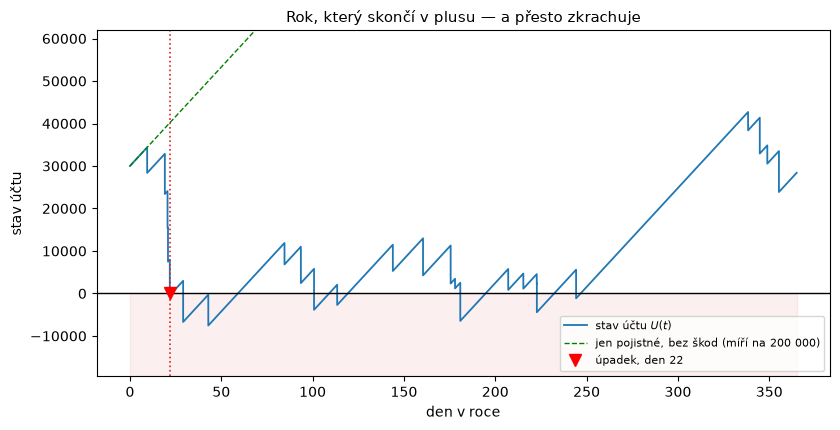

In [3]:
sc = SCENAR_A
u0 = 30_000
c = (sc["K"] - u0) / sc["N"]

random.seed(12)
for pokus in range(200_000):
    ud = udalosti_roku(sc)
    S, nejnizsi, ruina_v = 0.0, u0, None
    for t, x in ud:
        S += x
        stav = u0 + c * t - S
        if stav < 0 and ruina_v is None:
            ruina_v = t
        nejnizsi = min(nejnizsi, stav)
    if ruina_v is not None and S <= sc["K"] and ruina_v < 120:
        break

print(f"nalezeno po {pokus + 1} pokusech:")
print(f"  požadavků za rok: {len(ud)}, z toho do konce února: {sum(1 for t, _ in ud if t < 60)}")
print(f"  roční výplaty celkem: {mezery(S, ',.0f')}  (kapitál K = {mezery(sc['K'])}) → na konci roku v plusu")
print(f"  nejnižší stav účtu:   {mezery(nejnizsi, ',.0f')}  v den {ruina_v:.0f} → přesto úpadek")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
casy, stavy, S = [0.0], [u0], 0.0
for t, x in ud:
    casy += [t, t]
    stavy += [u0 + c * t - S, u0 + c * t - S - x]
    S += x
casy.append(sc["N"])
stavy.append(u0 + c * sc["N"] - S)
ax.plot(casy, stavy, lw=1.3, color="tab:blue", label="stav účtu $U(t)$")
ax.plot([0, sc["N"]], [u0, u0 + c * sc["N"]], "g--", lw=1,
        label=f"jen pojistné, bez škod (míří na {mezery(sc['K'])})")
ax.axhline(0, color="k", lw=1)
ax.axvline(ruina_v, color="tab:red", ls=":", lw=1.2)
ax.plot([ruina_v], [0], "rv", ms=9, label=f"úpadek, den {ruina_v:.0f}")
ax.fill_between([0, sc["N"]], [min(stavy) - 12_000] * 2, [0, 0], color="tab:red", alpha=0.07)
ax.set_ylim(min(stavy) - 12_000, max(stavy) * 1.45)
ax.set_xlabel("den v roce")
ax.set_ylabel("stav účtu")
ax.set_title("Rok, který skončí v plusu — a přesto zkrachuje", fontsize=11)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 2. Jedna nehoda, několik požadavků

Druhé zjednodušení: dosud byl každý požadavek samostatná událost. Ve skutečnosti jedna nehoda často zasáhne víc lidí najednou — srážka dvou aut znamená dva nároky ve **stejném okamžiku**.

Počet účastníků bereme z tabulky (losuje se základním algoritmem ze cvičení 3):

| účastníků $K$ | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| pravděpodobnost | 0.70 | 0.20 | 0.07 | 0.03 |

### Jak srovnávat poctivě

Kdybychom jen přidali shluky a nechali intenzitu nehod stejnou, vzrostl by $E[K]$krát **očekávaný počet požadavků** — a pojišťovna by krachovala víc prostě proto, že platí víc. O shlucích by to neřeklo nic.

Proto intenzitu nehod zároveň **podělíme $E[K]$**. Oba modely pak stojí v průměru stejně a rozdíl v riziku jde čistě na vrub shlukování.

Teoreticky to vychází ze zákona celkového rozptylu. Je-li $Y$ výplata z jedné nehody a $M$ počet nehod za rok,

$$E\,Y = E[K]\,E[X], \qquad D\,Y = E[K]\,D X + D[K]\,(E X)^2,$$
$$E\,T = E[M]\,E\,Y, \qquad D\,T = E[M]\,D\,Y + D[M]\,(E\,Y)^2 .$$

Střední hodnota vyjde stejně jako dřív, **rozptyl ne** — a to je celý vtip.

In [4]:
sc = SCENAR_A
ET0, VarT0 = teorie(sc, shluky=False)
ET1, VarT1 = teorie(sc, shluky=True)

print(f"{'model':>24s} {'E T':>12s} {'D T':>18s} {'sm. odchylka':>14s}")
print(f"{'bez shluků (cvičení 9)':>24s} {mezery(ET0, ',.0f'):>12s} {mezery(VarT0, ',.0f'):>18s} {mezery(math.sqrt(VarT0), ',.0f'):>14s}")
print(f"{'se shluky':>24s} {mezery(ET1, ',.0f'):>12s} {mezery(VarT1, ',.0f'):>18s} {mezery(math.sqrt(VarT1), ',.0f'):>14s}")
print(f"\nE T je stejné (o to jsme se postarali), ale směrodatná odchylka vzrostla "
      f"{math.sqrt(VarT1 / VarT0):.2f}krát.")

# kontrola: K = 1 musí dát přesně původní vzorec
EK_, VarK_ = EK, VarK
EK, VarK = 1.0, 0.0
assert abs(teorie(sc, shluky=True)[1] - VarT0) < 1e-6, "K = 1 musí reprodukovat původní model"
EK, VarK = EK_, VarK_
print("kontrola: pro K ≡ 1 dává vzorec se shluky přesně původní rozptyl ✓")

# a ověření simulací
n = 100_000
for shluky, nazev in ((False, "bez shluků"), (True, "se shluky")):
    vzorky = [sum(x for _, x in udalosti_roku(sc, shluky)) for _ in range(n)]
    m = sum(vzorky) / n
    var = sum((v - m) ** 2 for v in vzorky) / (n - 1)
    ET_, VarT_ = teorie(sc, shluky)
    check(f"E T ({nazev})", m, math.sqrt(var / n), ET_)
    print(f"    D T: simulace {mezery(var, ',.0f')}  (přesně {mezery(VarT_, ',.0f')})")

                   model          E T                D T   sm. odchylka
  bez shluků (cvičení 9)      121 667        871 944 444         29 529
               se shluky      121 667      1 541 252 914         39 259

E T je stejné (o to jsme se postarali), ale směrodatná odchylka vzrostla 1.33krát.
kontrola: pro K ≡ 1 dává vzorec se shluky přesně původní rozptyl ✓
E T (bez shluků): 121 680 +- 93  (přesně 121 667)
    D T: simulace 869 551 726  (přesně 871 944 444)
E T (se shluky): 121 588 +- 1.2e+02  (přesně 121 667)
    D T: simulace 1 535 239 761  (přesně 1 541 252 914)


Rozptyl vzrostl o tři čtvrtiny, přestože pojišťovna platí v průměru naprosto stejně. A protože o úpadku rozhoduje chvost rozdělení, ne jeho střed, musí to být vidět na riziku.

       u_0             bez shluků              se shluky   poměr
   100 000        0.01090 +- 0.00052        0.04952 +- 0.00108    4.54
    60 000        0.01800 +- 0.00066        0.07708 +- 0.00133    4.28
    30 000        0.05523 +- 0.00114        0.15748 +- 0.00182    2.85


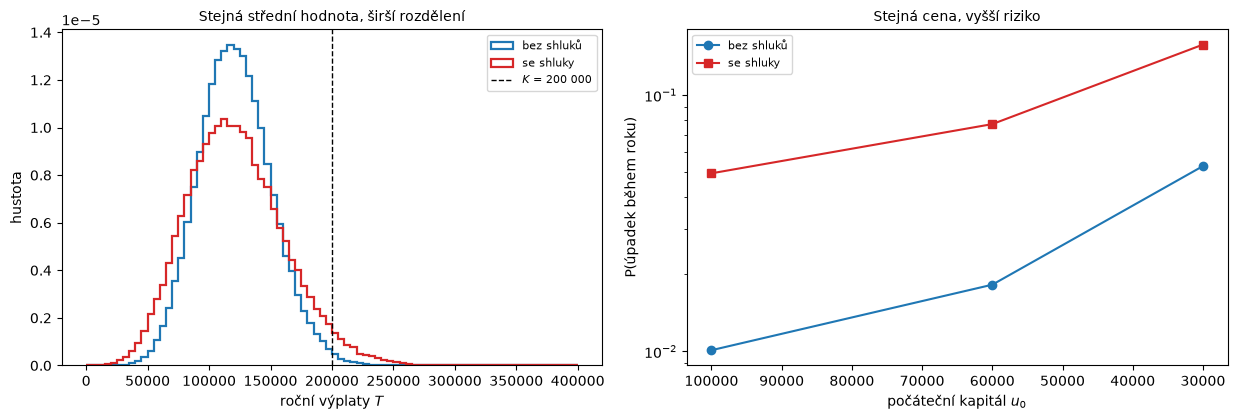

In [5]:
sc = SCENAR_A
print(f"{'u_0':>10s} {'bez shluků':>22s} {'se shluky':>22s} {'poměr':>7s}")
se_shluky = {}
for u0 in (100_000, 60_000, 30_000):
    a, sa = p_upadku(u0, sc, 40_000, shluky=False)
    b, sb = p_upadku(u0, sc, 40_000, shluky=True)
    se_shluky[u0] = b
    print(f"{mezery(u0, '10,d')} {a:>14.5f} +- {sa:.5f} {b:>14.5f} +- {sb:.5f} {b / a:>7.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
n = 60_000
for shluky, barva, nazev in ((False, "tab:blue", "bez shluků"), (True, "tab:red", "se shluky")):
    vz = [sum(x for _, x in udalosti_roku(sc, shluky)) for _ in range(n)]
    w = 400_000 / 80
    ax.hist(vz, bins=80, range=(0, 400_000), weights=[1 / (len(vz) * w)] * len(vz),
            histtype="step", lw=1.6, color=barva, label=nazev)
ax.axvline(sc["K"], color="k", ls="--", lw=1, label=f"$K$ = {mezery(sc['K'])}")
ax.set_xlabel("roční výplaty $T$")
ax.set_ylabel("hustota")
ax.set_title("Stejná střední hodnota, širší rozdělení", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
us = list(se_shluky)
ax.plot(us, [zaklad[u] for u in us], "o-", label="bez shluků")
ax.plot(us, [se_shluky[u] for u in us], "s-", color="tab:red", label="se shluky")
ax.set_xlabel("počáteční kapitál $u_0$")
ax.set_ylabel("P(úpadek během roku)")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_title("Stejná cena, vyšší riziko", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Levý graf ukazuje, co se stalo: obě rozdělení mají stejný střed, ale to se shluky je širší — a právě chvost za čárou $K$ rozhoduje o úpadku.

Pravý graf to převádí na čísla. **Při naprosto stejných očekávaných nákladech je úpadek několikrát pravděpodobnější**, jen proto, že škody chodí po skupinkách. To je jeden z důvodů, proč pojišťovny řeší zajištění právě pro katastrofy: nejde o to, kolik se průměrně vyplatí, ale jak moc to kolísá.

## 3. Lundbergova mez pro shluky

Ve cvičení o úpadku jsme používali Lundbergovu nerovnost

$$\psi(u_0) \le e^{-R u_0},$$

kde $R$ je kladný kořen rovnice $\lambda\,(M_X(R) - 1) = c\,R$. Pro shluky se zobecní překvapivě elegantně. Jedna **nehoda** teď vyplatí $Y = X_1 + \dots + X_K$, a protože jsou $X_i$ nezávislé na $K$,

$$M_Y(s) = E\big[M_X(s)^K\big] = G_K\big(M_X(s)\big),$$

kde $G_K(z) = \sum_k P(K = k)\,z^k$ je **vytvořující funkce počtu účastníků**. Lundbergova rovnice je pak

$$\lambda_{\text{nehod}}\,\Big(G_K\big(M_X(R)\big) - 1\Big) = c\,R .$$

Pro $K \equiv 1$ je $G_K(z) = z$ a dostaneme zpátky původní rovnici — to je naše kontrola.

In [6]:
def mgf_pozadavku(s, L):
    """E[e^{sX}] pro X = L·√γ, tj. hustotu 2x/L² na [0, L]."""
    if abs(s) < 1e-12:
        return 1.0
    return (2.0 / L**2) * (math.exp(s * L) * (L / s - 1 / s**2) + 1 / s**2)


def gk(z):
    """Vytvořující funkce počtu účastníků."""
    return sum(q * z**k for k, q in POCET_UCASTNIKU.items())


def lundberg_R(lam_udalosti, c, L, g=lambda z: z):
    """Kladný kořen rovnice λ(G_K(M_X(R)) - 1) = cR, půlením intervalu."""
    f = lambda R: lam_udalosti * (g(mgf_pozadavku(R, L)) - 1) - c * R
    lo, hi = 1e-12, 1e-3
    while f(hi) < 0:
        hi *= 1.5
    for _ in range(300):
        mid = (lo + hi) / 2
        if f(mid) < 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


sc = SCENAR_A
lam_pozadavku = sc["N"] * sc["p"]          # požadavků za rok (stejné v obou modelech)
lam_nehod = lam_pozadavku / EK             # nehod za rok ve shlukovém modelu
EX = 2 * sc["L"] / 3

print(f"požadavků za rok {lam_pozadavku:.2f}; ve shlukovém modelu {lam_nehod:.2f} nehod po {EK:.2f} požadavcích\n")
print(f"{'u_0':>9s} {'c':>10s} | {'R bez shluků':>13s} {'mez':>9s} | {'R se shluky':>13s} {'mez':>9s} | {'simulace':>9s}")
for u0 in (60_000, 30_000):
    c = sc["K"] - u0
    if c <= lam_pozadavku * EX:
        continue
    R0 = lundberg_R(lam_pozadavku, c, sc["L"])                 # G_K(z) = z
    R1 = lundberg_R(lam_nehod, c, sc["L"], gk)
    m0, m1 = math.exp(-R0 * u0), math.exp(-R1 * u0)
    print(f"{mezery(u0, '9,d')} {mezery(c, '10,d')} | {R0:>13.4e} {m0:>9.5f} | {R1:>13.4e} {m1:>9.5f} | {se_shluky[u0]:>9.5f}")
    assert se_shluky[u0] <= m1, "Lundbergova mez musí platit i pro shluky"

assert abs(lundberg_R(lam_pozadavku, 140_000, sc["L"], lambda z: z)
           - lundberg_R(lam_pozadavku, 140_000, sc["L"])) < 1e-12
print("\nkontrola: G_K(z) = z dává přesně původní R ✓")
print("Shluky snižují R, a tím zvedají mez — teorie tedy vyšší riziko potvrzuje,")
print("nejen že ho vidíme v simulaci.")

požadavků za rok 18.25; ve shlukovém modelu 12.76 nehod po 1.43 požadavcích

      u_0          c |  R bez shluků       mez |   R se shluky       mez |  simulace
   60 000    140 000 |    3.6370e-05   0.11279 |    2.0535e-05   0.29168 |   0.07708
   30 000    170 000 |    8.3552e-05   0.08155 |    4.5813e-05   0.25300 |   0.15748

kontrola: G_K(z) = z dává přesně původní R ✓
Shluky snižují R, a tím zvedají mez — teorie tedy vyšší riziko potvrzuje,
nejen že ho vidíme v simulaci.


## 4. Výplata netrvá nula

Třetí zjednodušení: dosud se platilo v okamžiku vzniku škody. Ve skutečnosti pojišťovna škodu nejdřív **zlikviduje** (prohlídka, doklady, schválení) a teprve pak pošle peníze. Mezi nehodou a výplatou tak uplyne nějaká doba $D$.

Zatím vezměme $D$ jako nezávislé u každého požadavku, $D \sim \operatorname{Exp}$ se střední hodnotou pár týdnů. Kontrola: $D = 0$ musí vrátit předchozí model.

Než to pustíme, stojí za to **tipnout si výsledek**. Zpoždění přece nic neušetří, celková částka je stejná…

…jenže peníze mezitím přitékají. Každý den odkladu je den, kdy na účet přibude pojistné, ale neubude výplata. **Zpoždění pojišťovně pomáhá** — a to dost výrazně.

In [7]:
sc = SCENAR_A
u0 = 30_000
print(f"u_0 = {mezery(u0)}, se shluky, M = 40 000 roků\n")
print(f"{'střední zpoždění':>18s} {'P(úpadek)':>20s} {'oproti okamžité výplatě':>24s}")
zpozdeni_dny = (0.0, 7.0, 14.0, 30.0, 60.0, 90.0)
p_zpozdeni = []
for d in zpozdeni_dny:
    kw = dict(shluky=True) if d == 0 else dict(shluky=True, zpozdeni=lambda d=d: random.expovariate(1 / d))
    ph, se = p_upadku(u0, sc, 40_000, **kw)
    p_zpozdeni.append(ph)
    pomer = "—" if d == 0 else f"{p_zpozdeni[0] / ph:.1f}x méně"
    print(f"{d:>14.0f} dní {ph:>14.5f} +- {se:.5f} {pomer:>24s}")

print("\nKontrola: řádek se zpožděním 0 je přesně model z oddílu 2 ✓")

u_0 = 30 000, se shluky, M = 40 000 roků

  střední zpoždění            P(úpadek)  oproti okamžité výplatě
             0 dní        0.15768 +- 0.00182                        —
             7 dní        0.12105 +- 0.00163                1.3x méně
            14 dní        0.09842 +- 0.00149                1.6x méně
            30 dní        0.05820 +- 0.00117                2.7x méně
            60 dní        0.02165 +- 0.00073                7.3x méně
            90 dní        0.00790 +- 0.00044               20.0x méně

Kontrola: řádek se zpožděním 0 je přesně model z oddílu 2 ✓


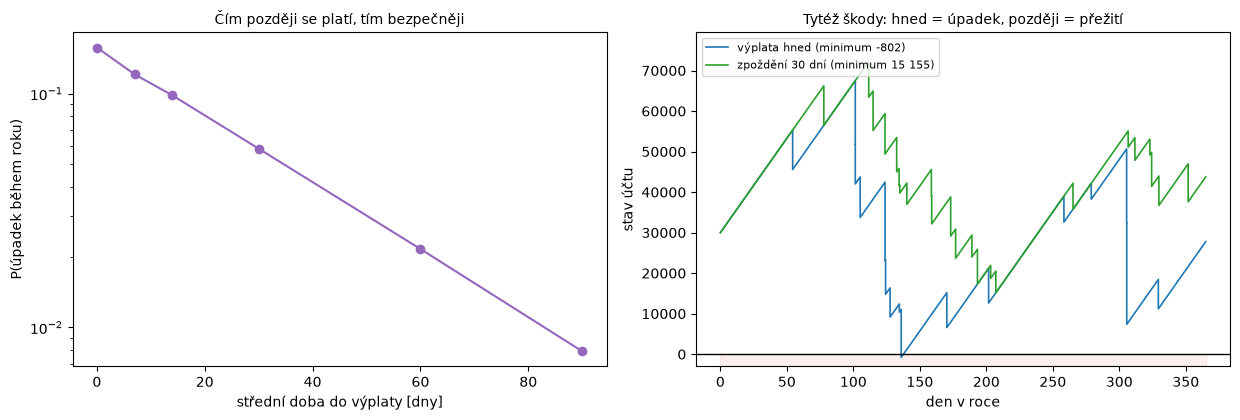

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.plot(zpozdeni_dny, p_zpozdeni, "o-", color="tab:purple")
ax.set_xlabel("střední doba do výplaty [dny]")
ax.set_ylabel("P(úpadek během roku)")
ax.set_yscale("log")
ax.set_title("Čím později se platí, tím bezpečněji", fontsize=10)

# proč: najdeme rok, který při okamžité výplatě zkrachuje a se zpožděním přežije
ax = axes[1]
c = (sc["K"] - u0) / sc["N"]


def prubeh(plan):
    """Stav účtu v čase pro daný plán výplat; vrací (časy, stavy, nejnižší stav)."""
    casy, stavy, S = [0.0], [u0], 0.0
    for t, x in plan:
        if t > sc["N"]:
            break
        casy += [t, t]
        stavy += [u0 + c * t - S, u0 + c * t - S - x]
        S += x
    casy.append(sc["N"])
    stavy.append(u0 + c * sc["N"] - S)
    return casy, stavy, min(stavy)


random.seed(3)
for pokus in range(200_000):
    ud = udalosti_roku(sc, shluky=True)
    hned = sorted(ud)
    pozde = sorted((t + random.expovariate(1 / 30.0), x) for t, x in ud)
    c1, s1, min1 = prubeh(hned)
    c2, s2, min2 = prubeh(pozde)
    if min1 < 0 < min2:                      # hned = úpadek, se zpožděním přežije
        break

ax.plot(c1, s1, lw=1.2, color="tab:blue", label=f"výplata hned (minimum {mezery(min1, ',.0f')})")
ax.plot(c2, s2, lw=1.2, color="tab:green", label=f"zpoždění 30 dní (minimum {mezery(min2, ',.0f')})")
ax.axhline(0, color="k", lw=1)
ax.fill_between([0, sc["N"]], [min1 * 1.3 - 2000] * 2, [0, 0], color="tab:red", alpha=0.07)
ax.set_ylim(min1 * 1.3 - 2000, max(max(s1), max(s2)) * 1.10)
ax.set_xlabel("den v roce")
ax.set_ylabel("stav účtu")
ax.set_title("Tytéž škody: hned = úpadek, později = přežití", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

Pravý graf ukazuje mechanismus na jednom roce: jsou to **tytéž škody ve stejném pořadí**, jen posunuté. Zelená křivka stíhá mezitím vybrat pojistné, takže se nedostane tak hluboko.

Pozor ale na dvě věci, aby z toho nevznikl nesmysl:

- Část výplat se odsune **až za konec roku**, takže se v našem horizontu vůbec neprojeví. Z pohledu jednoho roku to vypadá jako čistý zisk, ve skutečnosti je to dluh přenesený dál. Poctivější odpověď by potřebovala víceletý model.
- Zpoždění je tu **nezávislé na zatížení**. To je právě ten předpoklad, který v praxi padá jako první.

## 5. Likvidátorů je konečný počet

Čtvrté zjednodušení: zpoždění nespadne z nebe. Škody likvidují lidé a těch je omezený počet. Požadavky se jim hromadí ve frontě — a tím jsme přesně u **systému hromadné obsluhy** ze sešitu `extra/ch07_hromadna_obsluha`.

Model: požadavky přicházejí tak, jak je generuje pojišťovna, $c$ likvidátorů je obsluhuje v pořadí příchodu a doba likvidace je $\operatorname{Exp}$ se střední hodnotou $1/\mu$. Doba do výplaty je **čekání ve frontě plus doba likvidace**.

Teoretická kontrola: bez shluků jsou příchody (skoro) poissonovské, takže pro jednoho likvidátora platí M/M/1 a

$$W = \frac{1}{\mu - \lambda}, \qquad \varrho = \frac{\lambda}{\mu}.$$

**Se shluky to přestane platit přesně.** Požadavky přicházejí po dávkách, což je model $M^{[X]}/M/1$, a dávky čekají déle než stejný počet rovnoměrně rozprostřených požadavků. Vzorce výše tedy budou jen přibližné — a rozdíl si změříme.

In [9]:
def fronta_doby(casy, likvidatoru, stredni_likvidace):
    """FIFO fronta: vrátí dobu od příchodu do vyřízení pro každý požadavek."""
    volni = [0.0] * likvidatoru
    heapq.heapify(volni)
    doby = []
    for t in casy:
        uvolni_se = heapq.heappop(volni)
        konec = max(t, uvolni_se) + random.expovariate(1 / stredni_likvidace)
        heapq.heappush(volni, konec)
        doby.append(konec - t)
    return doby


def casy_za_roky(sc, roku, shluky):
    """Časy příchodu požadavků za několik let v kuse."""
    out = []
    for r in range(roku):
        out += [r * sc["N"] + t for t, _ in udalosti_roku(sc, shluky)]
    out.sort()
    return out


sc = SCENAR_A
STREDNI_LIKVIDACE = 10.0                      # dní na jeden případ
lam_den = sc["p"]                             # požadavků za den
mu_den = 1 / STREDNI_LIKVIDACE
print(f"λ = {lam_den:.4f} požadavků/den, μ = {mu_den:.4f}/den, ϱ = {lam_den / mu_den:.2f}")
print(f"teorie M/M/1:  W = 1/(μ - λ) = {1 / (mu_den - lam_den):.2f} dní\n")

print(f"{'příchody':>14s} {'W ze simulace':>16s} {'M/M/1 teorie':>14s}")
for shluky, nazev in ((False, "bez shluků"), (True, "se shluky")):
    casy = casy_za_roky(sc, 400, shluky)
    d = fronta_doby(casy, 1, STREDNI_LIKVIDACE)
    d = d[len(d) // 5:]                       # zahodíme rozjezd (přechodový jev, cvičení o frontách)
    print(f"{nazev:>14s} {sum(d) / len(d):>13.2f} dní {1 / (mu_den - lam_den):>11.2f} dní")

print("\nBez shluků simulace sedí na M/M/1. Se shluky čeká požadavek výrazně déle,")
print("přestože jich za rok přijde stejně — dávka si musí počkat sama na sebe.")

λ = 0.0500 požadavků/den, μ = 0.1000/den, ϱ = 0.50
teorie M/M/1:  W = 1/(μ - λ) = 20.00 dní

      příchody    W ze simulace   M/M/1 teorie
    bez shluků         20.08 dní       20.00 dní
     se shluky         28.17 dní       20.00 dní

Bez shluků simulace sedí na M/M/1. Se shluky čeká požadavek výrazně déle,
přestože jich za rok přijde stejně — dávka si musí počkat sama na sebe.


Co se stane, když likvidace trvá déle (ϱ se blíží jedné):

 střední likvidace       ϱ    W simulace    W teorie
          10.0 dní   0.500       18.3 dní     20.0 dní
          14.0 dní   0.700       40.4 dní     46.7 dní
          17.0 dní   0.850      139.6 dní    113.3 dní
          19.0 dní   0.950      350.2 dní    380.0 dní
          19.5 dní   0.975      635.7 dní    780.0 dní


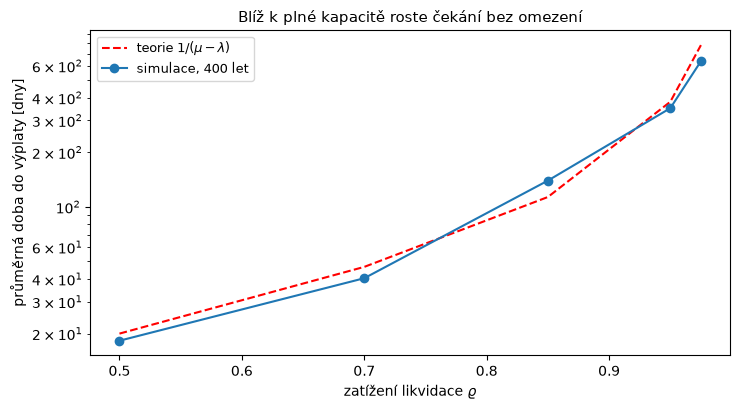


Do ϱ ≈ 0.7 simulace sedí. Pak se od teorie rozchází, a to v OBOU směrech —
není to chyba vzorce, ale toho, že se fronta při vysokém zatížení ustaluje
tak pomalu, že jí ani 400 let nestačí. Zkuste buňku pustit znovu: poslední
řádky vyjdou pokaždé výrazně jinak. Je to přechodový jev ze sešitu o frontách.


In [10]:
print("Co se stane, když likvidace trvá déle (ϱ se blíží jedné):\n")
print(f"{'střední likvidace':>18s} {'ϱ':>7s} {'W simulace':>13s} {'W teorie':>11s}")
zatizeni, W_sim, W_teor = [], [], []
for ms in (10.0, 14.0, 17.0, 19.0, 19.5):
    rho = lam_den * ms
    casy = casy_za_roky(sc, 400, False)
    d = fronta_doby(casy, 1, ms)
    d = d[len(d) // 5:]
    w_s = sum(d) / len(d)
    w_t = 1 / (1 / ms - lam_den)
    zatizeni.append(rho); W_sim.append(w_s); W_teor.append(w_t)
    print(f"{ms:>14.1f} dní {rho:>7.3f} {w_s:>10.1f} dní {w_t:>8.1f} dní")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(zatizeni, W_teor, "r--", label=r"teorie $1/(\mu-\lambda)$")
ax.plot(zatizeni, W_sim, "o-", label="simulace, 400 let")
ax.set_xlabel(r"zatížení likvidace $\varrho$")
ax.set_ylabel("průměrná doba do výplaty [dny]")
ax.set_yscale("log")
ax.set_title("Blíž k plné kapacitě roste čekání bez omezení", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("\nDo ϱ ≈ 0.7 simulace sedí. Pak se od teorie rozchází, a to v OBOU směrech —")
print("není to chyba vzorce, ale toho, že se fronta při vysokém zatížení ustaluje")
print("tak pomalu, že jí ani 400 let nestačí. Zkuste buňku pustit znovu: poslední")
print("řádky vyjdou pokaždé výrazně jinak. Je to přechodový jev ze sešitu o frontách.")

Poslední graf je druhá tvář téhož rizika. Pojišťovna nemusí zkrachovat jen tím, že nemá peníze — může se zadrhnout i **provozně**: když likvidace nestíhá, doba do výplaty roste bez omezení, klienti čekají měsíce a regulátor přichází dřív než insolvence.

A všimněte si pořádně posledních řádků výpisu. Do $\varrho \approx 0.7$ simulace na teorii sedí, pak se od ní rozchází — a pokaždé jinak, jednou nad, jednou pod. Není to chyba vzorce: při vysokém zatížení se fronta ustaluje tak pomalu, že jí ani 400 let nestačí, takže měříme pořád ještě rozjezd. Pusťte tu buňku dvakrát a porovnejte poslední dva řádky.

Tohle je mimochodem dobrý důvod, proč je v tomhle sešitu u každého rozšíření kontrola. Kdybychom vzorec neznali, dalo by se z těch čísel usoudit skoro cokoliv.

## Shrnutí

| Zjednodušení | Co se stane, když ho odebereme | Kontrola |
|---|---|---|
| kapitál hned na začátku | záleží na pořadí; při $u_0 = 30\,000$ je úpadek ~7× pravděpodobnější | $u_0 = K$ vrací cvičení 9 |
| nezávislé požadavky | při **stejných** očekávaných nákladech je úpadek ~4× pravděpodobnější | $E T$ sedí, $K \equiv 1$ vrací původní rozptyl |
| — | Lundbergova mez: $\lambda_{\text{nehod}}(G_K(M_X(R)) - 1) = cR$ | $G_K(z) = z$ vrací původní $R$ |
| okamžitá výplata | zpoždění pojišťovně **pomáhá**, peníze mezitím přitečou | $D = 0$ vrací předchozí model |
| neomezená likvidace | fronta; při $\varrho \to 1$ roste čekání bez omezení | bez shluků sedí M/M/1 |

Tři věci, které si odnést:

1. **Rozhoduje rozptyl, ne střední hodnota.** Shluky nezdražily ani korunu a riziko přesto vyskočilo několikanásobně. Proto se pojišťovny jistí proti katastrofám, ne proti průměru.
2. **Zjednodušení není lež, ale má cenu — a ta se dá změřit.** Každý oddíl ukázal, kolik konkrétně to které zjednodušení stálo. To je užitečnější než model „co nejvěrnější", u kterého nevíte, co dělá co.
3. **Realističtější model potřebuje víc kontrol, ne míň.** Každé rozšíření si tu drží limitní případ nebo vzorec. Jinak se chyba tváří jako objev — a čím složitější model, tím snazší je si toho nevšimnout.

### Zkuste si

1. **Zamítnuté požadavky.** Ať pojišťovna každý požadavek nezávisle zamítne s pravděpodobností $1-q$. Ukažte, že je to přesně původní model s $p \to pq$, a ověřte simulací. (Poučení: ne každé „rozšíření" je nový model.)
2. **Spoluúčast.** Pojišťovna platí $\max(X - d, 0)$. Spočítejte přesně $E$ a $D$ nové výplaty pro hustotu $2r$ a najděte $d$, při kterém klesne riziko úpadku na polovinu.
3. Rozdělení počtu účastníků nahraďte těžším (třeba $K$ až 10 u hromadné nehody) při stejném $E[K]$. O kolik vzroste riziko?
4. Zpoždění udělejte **závislé na zatížení**: při víc otevřených případech ať likvidace trvá déle. Pomáhá zpoždění pořád?
5. Spočítejte, kolik likvidátorů je potřeba, aby střední doba do výplaty zůstala pod 30 dny i ve shlukovém modelu.
6. Spojte oddíly 4 a 5: použijte dobu z fronty jako zpoždění výplaty a změřte riziko úpadku. Vyruší se obě zjištění, nebo jedno převáží?
7. Rozšiřte model na **pět let** a sledujte, jestli zpoždění pořád pomáhá, když se odsunuté výplaty vracejí v dalším roce.